# UrbanPulse AI — Spatial Modeling

## Stage 6.1: Multi-Station Air Quality Data Integration

**Research objective:** Investigate whether measurements from multiple monitoring stations provide additional predictive information for one-hour-ahead PM2.5 forecasting at a target station.

**Dataset:** UCI Beijing Multi-Site Air Quality Dataset  
**Temporal resolution:** Hourly  
**Study period:** March 2013 – February 2017  
**Spatial units:** 12 monitoring stations

### Methodological plan

1. Load and validate all 12 station files.
2. reconstruct timestamps and verify temporal coverage.
3. quantify missing observations and station-level data quality.
4. align stations using common timestamps.
5. verify station coordinates before making geographic or distance-based claims.
6. establish a temporal baseline and compare it with a multi-station predictive model.

**Important limitation:** The station CSV files do not contain latitude or longitude. Geographic analysis will require a separately verified coordinate source. Timestamp alignment alone establishes temporal correspondence, not geographic proximity or causal influence.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\UrbanPulse-AI")
DATA_DIR = PROJECT_DIR / "data" / "raw" / "beijing" / "extracted"
REPORT_DIR = PROJECT_DIR / "reports"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "spatial"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

station_files = sorted(
    DATA_DIR.rglob("PRSA_Data_*_20130301-20170228.csv")
)

print("Project directory:", PROJECT_DIR)
print("Station files found:", len(station_files))

if len(station_files) != 12:
    raise ValueError(
        f"Expected 12 station files; found {len(station_files)}."
    )

for path in station_files:
    print(path.name)

Project directory: C:\UrbanPulse-AI
Station files found: 12
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [2]:
spatial_frames = []

for path in station_files:
    station_df = pd.read_csv(path)

    required_columns = {
        "year", "month", "day", "hour",
        "PM2.5", "station"
    }
    missing_columns = required_columns - set(station_df.columns)

    if missing_columns:
        raise ValueError(
            f"{path.name} is missing columns: {sorted(missing_columns)}"
        )

    station_df["timestamp"] = pd.to_datetime(
        station_df[["year", "month", "day", "hour"]]
        .rename(columns={
            "year": "year",
            "month": "month",
            "day": "day",
            "hour": "hour",
        }),
        errors="coerce"
    )

    station_df["source_file"] = path.name
    spatial_frames.append(station_df)

spatial_df = pd.concat(spatial_frames, ignore_index=True)

spatial_df = spatial_df.sort_values(
    ["station", "timestamp"]
).reset_index(drop=True)

print("Combined shape:", spatial_df.shape)
print("Stations:", spatial_df["station"].nunique())
print("Invalid timestamps:", spatial_df["timestamp"].isna().sum())
print("Duplicate station-timestamp pairs:",
      spatial_df.duplicated(["station", "timestamp"]).sum())

print("\nRows per station:")
display(spatial_df.groupby("station").size().rename("Rows").to_frame())

Combined shape: (420768, 20)
Stations: 12
Invalid timestamps: 0
Duplicate station-timestamp pairs: 0

Rows per station:


,Rows
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


In [3]:
station_quality_records = []

for station, group in spatial_df.groupby("station"):
    group = group.sort_values("timestamp")

    station_quality_records.append({
        "Station": station,
        "Rows": len(group),
        "Start": group["timestamp"].min(),
        "End": group["timestamp"].max(),
        "Unique_Timestamps": group["timestamp"].nunique(),
        "Duplicate_Timestamps": int(
            group["timestamp"].duplicated().sum()
        ),
        "Missing_PM25": int(group["PM2.5"].isna().sum()),
        "PM25_Missing_Percent": float(
            group["PM2.5"].isna().mean() * 100
        ),
        "Negative_PM25": int((group["PM2.5"] < 0).sum()),
    })

station_quality = (
    pd.DataFrame(station_quality_records)
    .sort_values("Station")
    .reset_index(drop=True)
)

display(station_quality.round(3))

station_quality.to_csv(
    REPORT_DIR / "spatial_station_quality.csv",
    index=False
)

print("Saved:", REPORT_DIR / "spatial_station_quality.csv")

C:\Users\HP\AppData\Local\Temp\ipykernel_19940\3676554755.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(station_quality.round(3))


,Station,Rows,Start,End,Unique_Timestamps,Duplicate_Timestamps,Missing_PM25,PM25_Missing_Percent,Negative_PM25
0,Aotizhongxin,35064,2013-03-01,2017-02-28 23:00:00,35064,0,925,2.638,0
1,Changping,35064,2013-03-01,2017-02-28 23:00:00,35064,0,774,2.207,0
2,Dingling,35064,2013-03-01,2017-02-28 23:00:00,35064,0,779,2.222,0
3,Dongsi,35064,2013-03-01,2017-02-28 23:00:00,35064,0,750,2.139,0
4,Guanyuan,35064,2013-03-01,2017-02-28 23:00:00,35064,0,616,1.757,0
5,Gucheng,35064,2013-03-01,2017-02-28 23:00:00,35064,0,646,1.842,0
6,Huairou,35064,2013-03-01,2017-02-28 23:00:00,35064,0,953,2.718,0
7,Nongzhanguan,35064,2013-03-01,2017-02-28 23:00:00,35064,0,628,1.791,0
8,Shunyi,35064,2013-03-01,2017-02-28 23:00:00,35064,0,913,2.604,0
9,Tiantan,35064,2013-03-01,2017-02-28 23:00:00,35064,0,677,1.931,0


Saved: C:\UrbanPulse-AI\reports\spatial_station_quality.csv


,Value
Unique_Hourly_Timestamps,35064
Hours_With_All_12_Stations,28663
Hours_With_At_Least_10_Stations,34796
Hours_With_At_Least_6_Stations,34971
Hours_With_At_Least_1_Station,34983


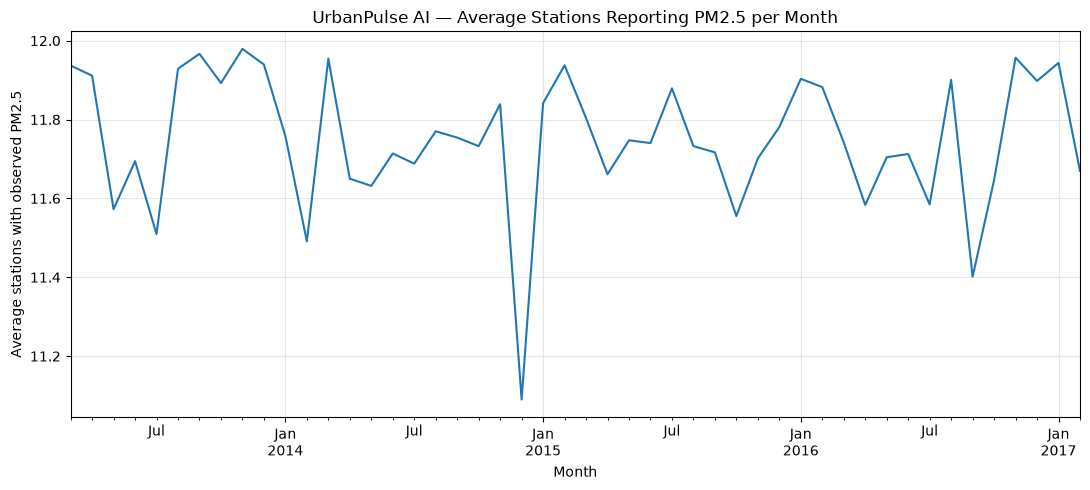

In [4]:
pm25_wide = spatial_df.pivot(
    index="timestamp",
    columns="station",
    values="PM2.5"
).sort_index()

station_count_per_hour = pm25_wide.notna().sum(axis=1)

alignment_summary = pd.Series({
    "Unique_Hourly_Timestamps": len(pm25_wide),
    "Hours_With_All_12_Stations": int(
        (station_count_per_hour == 12).sum()
    ),
    "Hours_With_At_Least_10_Stations": int(
        (station_count_per_hour >= 10).sum()
    ),
    "Hours_With_At_Least_6_Stations": int(
        (station_count_per_hour >= 6).sum()
    ),
    "Hours_With_At_Least_1_Station": int(
        (station_count_per_hour >= 1).sum()
    ),
})

display(alignment_summary.to_frame("Value"))

plt.figure(figsize=(11, 5))
station_count_per_hour.resample("MS").mean().plot()
plt.title("UrbanPulse AI — Average Stations Reporting PM2.5 per Month")
plt.xlabel("Month")
plt.ylabel("Average stations with observed PM2.5")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
station,,,,,,,,,,,,
Aotizhongxin,1.000,0.857,0.834,0.958,0.963,0.908,0.854,0.955,0.901,0.942,0.946,0.931
Changping,0.857,1.000,0.925,0.829,0.849,0.864,0.866,0.820,0.821,0.818,0.875,0.806
Dingling,0.834,0.925,1.000,0.805,0.829,0.844,0.865,0.795,0.810,0.790,0.847,0.778
Dongsi,0.958,0.829,0.805,1.000,0.969,0.903,0.836,0.964,0.892,0.964,0.933,0.953
Guanyuan,0.963,0.849,0.829,0.969,1.000,0.928,0.850,0.949,0.886,0.957,0.956,0.953
Gucheng,0.908,0.864,0.844,0.903,0.928,1.000,0.859,0.884,0.862,0.894,0.936,0.896
Huairou,0.854,0.866,0.865,0.836,0.850,0.859,1.000,0.823,0.901,0.823,0.855,0.813
Nongzhanguan,0.955,0.820,0.795,0.964,0.949,0.884,0.823,1.000,0.889,0.957,0.918,0.942
Shunyi,0.901,0.821,0.810,0.892,0.886,0.862,0.901,0.889,1.000,0.883,0.876,0.875


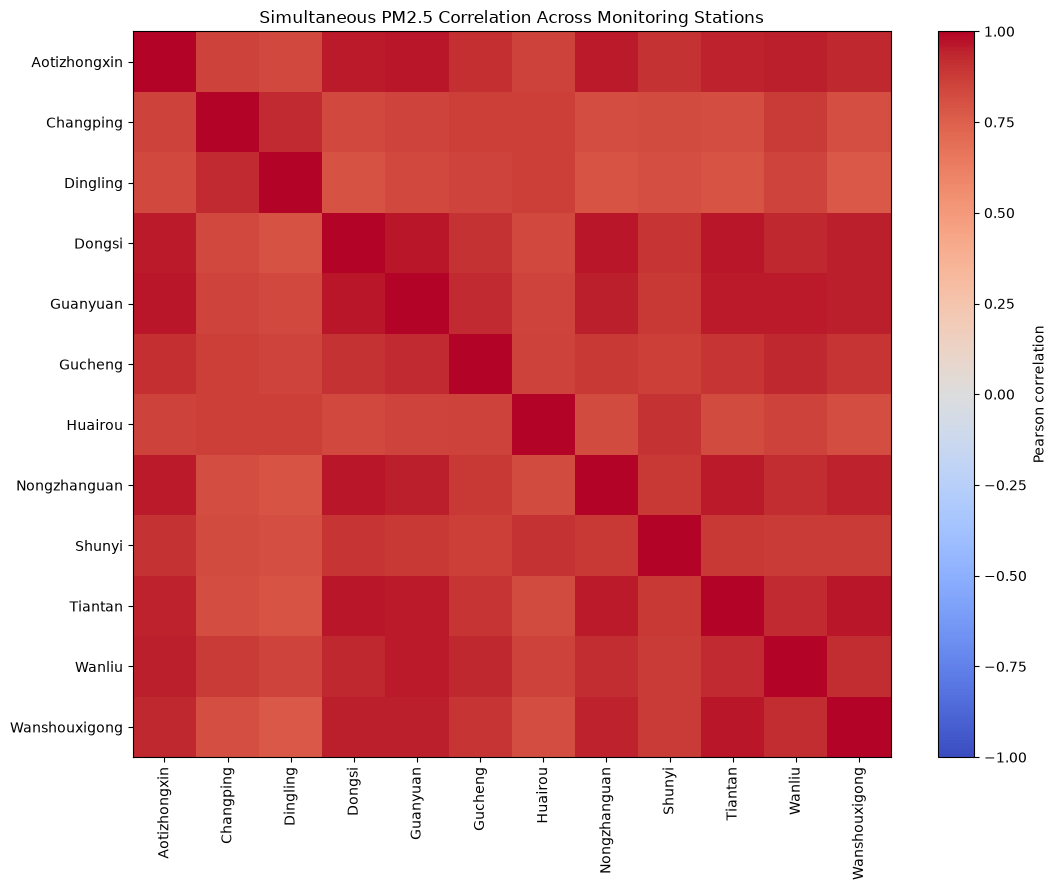

Saved: C:\UrbanPulse-AI\reports\spatial_pm25_correlation.csv


In [5]:
station_correlation = pm25_wide.corr(
    method="pearson",
    min_periods=500
)

display(station_correlation.round(3))

plt.figure(figsize=(11, 9))
image = plt.imshow(
    station_correlation,
    vmin=-1,
    vmax=1,
    aspect="auto",
    cmap="coolwarm"
)

plt.colorbar(image, label="Pearson correlation")
plt.xticks(
    range(len(station_correlation.columns)),
    station_correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(station_correlation.index)),
    station_correlation.index
)
plt.title("Simultaneous PM2.5 Correlation Across Monitoring Stations")
plt.tight_layout()
plt.show()

station_correlation.to_csv(
    REPORT_DIR / "spatial_pm25_correlation.csv"
)
print("Saved:", REPORT_DIR / "spatial_pm25_correlation.csv")

In [6]:
target_station = "Aotizhongxin"

if target_station not in pm25_wide.columns:
    raise ValueError(f"Target station not found: {target_station}")

all_station_mask = pm25_wide.notna().all(axis=1)
target_mask = pm25_wide[target_station].notna()

common_station_mask = all_station_mask & target_mask

coverage_summary = pd.Series({
    "Total_Hourly_Timestamps": len(pm25_wide),
    "Target_Observed_Timestamps": int(target_mask.sum()),
    "All_12_Stations_Observed": int(all_station_mask.sum()),
    "All_12_Stations_Observed_Percent": float(
        all_station_mask.mean() * 100
    ),
})

display(coverage_summary.to_frame("Value"))

print("\nTarget station:", target_station)
print("All-station complete timestamps:", int(common_station_mask.sum()))
print("Timestamps removed by complete-case restriction:",
      int((~common_station_mask).sum()))

,Value
Total_Hourly_Timestamps,35064.000000
Target_Observed_Timestamps,34139.000000
All_12_Stations_Observed,28663.000000
All_12_Stations_Observed_Percent,81.744809



Target station: Aotizhongxin
All-station complete timestamps: 28663
Timestamps removed by complete-case restriction: 6401


In [7]:
spatial_df.to_csv(
    PROCESSED_DIR / "beijing_all_stations_long.csv",
    index=False
)

pm25_wide.to_csv(
    PROCESSED_DIR / "beijing_pm25_wide.csv",
    index_label="timestamp"
)

common_pm25 = pm25_wide.loc[common_station_mask].copy()

common_pm25.to_csv(
    PROCESSED_DIR / "beijing_pm25_common_timestamps.csv",
    index_label="timestamp"
)

print("Saved spatial dataset artifacts:")
print(PROCESSED_DIR / "beijing_all_stations_long.csv")
print(PROCESSED_DIR / "beijing_pm25_wide.csv")
print(PROCESSED_DIR / "beijing_pm25_common_timestamps.csv")
print("Long-form shape:", spatial_df.shape)
print("Wide PM2.5 shape:", pm25_wide.shape)
print("Complete-case shape:", common_pm25.shape)

Saved spatial dataset artifacts:
C:\UrbanPulse-AI\data\processed\spatial\beijing_all_stations_long.csv
C:\UrbanPulse-AI\data\processed\spatial\beijing_pm25_wide.csv
C:\UrbanPulse-AI\data\processed\spatial\beijing_pm25_common_timestamps.csv
Long-form shape: (420768, 20)
Wide PM2.5 shape: (35064, 12)
Complete-case shape: (28663, 12)


In [8]:
coordinate_candidates = [
    col for col in spatial_df.columns
    if any(term in col.lower() for term in [
        "latitude", "longitude", "lat", "lon", "gps"
    ])
]

print("Potential coordinate columns:", coordinate_candidates)

if not coordinate_candidates:
    print(
        "No latitude/longitude fields found in the station CSVs. "
        "Geographic distance analysis is deferred until coordinates "
        "are obtained from a verifiable source."
    )

Potential coordinate columns: []
No latitude/longitude fields found in the station CSVs. Geographic distance analysis is deferred until coordinates are obtained from a verifiable source.


## 6.2 — Geographic Station Metadata and Distance Analysis

The original station CSV files do not contain geographic coordinates. This section adds published longitude and latitude values for the 12 monitoring stations.

Pairwise great-circle distances are calculated using the haversine formula. These distances provide a geographic reference for examining station relationships; they do not directly measure pollution transport or atmospheric influence.

**Source:** Published station-coordinate table in research on the Beijing Multi-Site Air Quality Dataset. Coordinate values are treated as approximate published station locations, not survey-grade measurements.

In [9]:
station_coordinates = pd.DataFrame([
    ("Aotizhongxin",    116.397, 39.982),
    ("Changping",       116.230, 40.217),
    ("Dingling",        116.220, 40.292),
    ("Dongsi",          116.417, 39.929),
    ("Guanyuan",        116.339, 39.929),
    ("Gucheng",         116.184, 39.914),
    ("Huairou",         116.628, 40.328),
    ("Nongzhanguan",    116.461, 39.937),
    ("Shunyi",          116.655, 40.127),
    ("Tiantan",         116.407, 39.886),
    ("Wanliu",          116.287, 39.987),
    ("Wanshouxigong",   116.352, 39.878),
], columns=["station", "longitude", "latitude"])

data_stations = set(spatial_df["station"].unique())
coordinate_stations = set(station_coordinates["station"])

print("Stations in data:", len(data_stations))
print("Stations with coordinates:", len(coordinate_stations))
print("Missing coordinates:", sorted(data_stations - coordinate_stations))
print("Unexpected coordinate entries:",
      sorted(coordinate_stations - data_stations))

if data_stations != coordinate_stations:
    raise ValueError("Coordinate table does not match the station dataset.")

display(station_coordinates)

station_coordinates.to_csv(
    REPORT_DIR / "spatial_station_coordinates.csv",
    index=False
)

print("Saved coordinate table.")

Stations in data: 12
Stations with coordinates: 12
Missing coordinates: []
Unexpected coordinate entries: []


,station,longitude,latitude
0,Aotizhongxin,116.397,39.982
1,Changping,116.230,40.217
2,Dingling,116.220,40.292
3,Dongsi,116.417,39.929
4,Guanyuan,116.339,39.929
5,Gucheng,116.184,39.914
6,Huairou,116.628,40.328
7,Nongzhanguan,116.461,39.937
8,Shunyi,116.655,40.127
9,Tiantan,116.407,39.886


Saved coordinate table.


In [10]:
# Haversine distance in kilometres
EARTH_RADIUS_KM = 6371.0088

coords_rad = np.radians(
    station_coordinates[["latitude", "longitude"]].to_numpy()
)

lat = coords_rad[:, 0]
lon = coords_rad[:, 1]

delta_lat = lat[:, None] - lat[None, :]
delta_lon = lon[:, None] - lon[None, :]

a = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat[:, None])
    * np.cos(lat[None, :])
    * np.sin(delta_lon / 2) ** 2
)

a = np.clip(a, 0, 1)

distance_values = (
    2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))
)

station_names = station_coordinates["station"].tolist()

distance_matrix = pd.DataFrame(
    distance_values,
    index=station_names,
    columns=station_names
)

display(distance_matrix.round(2))

distance_matrix.to_csv(
    REPORT_DIR / "spatial_station_distance_matrix_km.csv"
)

# List each pair only once, excluding self-distance
upper_triangle = np.triu(
    np.ones(distance_matrix.shape, dtype=bool),
    k=1
)

distance_pairs = (
    distance_matrix.where(upper_triangle)
    .stack()
    .rename("Distance_km")
    .reset_index()
)

distance_pairs.columns = ["Station_A", "Station_B", "Distance_km"]

print("Closest station pairs:")
display(
    distance_pairs.sort_values("Distance_km")
    .head(10)
    .round(3)
)

print("Saved distance matrix.")

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,0.00,29.74,37.61,6.13,7.69,19.67,43.19,7.40,27.24,10.71,9.39,12.18
Changping,29.74,0.00,8.38,35.76,33.34,33.92,35.95,36.82,37.47,39.77,26.03,39.10
Dingling,37.61,8.38,0.00,43.70,41.61,42.14,34.83,44.48,41.24,47.87,34.39,47.38
Dongsi,6.13,35.76,43.70,0.00,6.65,19.94,47.86,3.86,29.92,4.86,12.82,7.93
Guanyuan,7.69,33.34,41.61,6.65,0.00,13.32,50.72,10.44,34.77,7.52,7.83,5.78
Gucheng,19.67,33.92,42.14,19.94,13.32,0.00,59.54,23.76,46.58,19.28,11.96,14.88
Huairou,43.19,35.95,34.83,47.86,50.72,59.54,0.00,45.74,22.47,52.62,47.72,55.27
Nongzhanguan,7.40,36.82,44.48,3.86,10.44,23.76,45.74,0.00,26.82,7.31,15.84,11.38
Shunyi,27.24,37.47,41.24,29.92,34.77,46.58,22.47,26.82,0.00,34.12,34.98,37.85
Tiantan,10.71,39.77,47.87,4.86,7.52,19.28,52.62,7.31,34.12,0.00,15.19,4.78


Closest station pairs:


,Station_A,Station_B,Distance_km
43,Dongsi,Nongzhanguan,3.856
119,Tiantan,Wanshouxigong,4.777
45,Dongsi,Tiantan,4.857
59,Guanyuan,Wanshouxigong,5.778
3,Aotizhongxin,Dongsi,6.135
40,Dongsi,Guanyuan,6.651
93,Nongzhanguan,Tiantan,7.306
7,Aotizhongxin,Nongzhanguan,7.402
57,Guanyuan,Tiantan,7.517
4,Aotizhongxin,Guanyuan,7.692


Saved distance matrix.


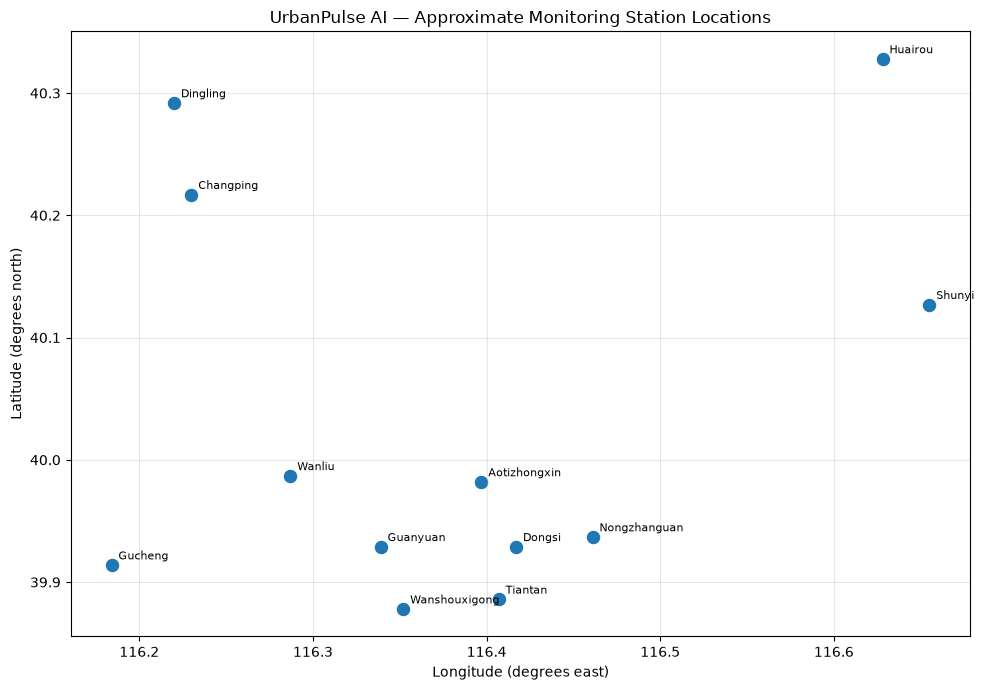

In [11]:
plt.figure(figsize=(10, 7))

plt.scatter(
    station_coordinates["longitude"],
    station_coordinates["latitude"],
    s=75
)

for _, row in station_coordinates.iterrows():
    plt.annotate(
        row["station"],
        (row["longitude"], row["latitude"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Longitude (degrees east)")
plt.ylabel("Latitude (degrees north)")
plt.title("UrbanPulse AI — Approximate Monitoring Station Locations")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6.3 — One-Hour-Ahead Multi-Station Forecasting

At each hourly timestamp \(t\), the models use PM2.5 measurements available at time \(t\) to predict Aotizhongxin PM2.5 at \(t+1\).

The experiment uses chronological partitions:

- Training targets through 2015-12-18 15:00
- Validation targets from 2015-12-18 16:00 through 2016-07-24 19:00
- Test targets from 2016-07-24 20:00 onward

The imputer is fitted only on training features. All models are evaluated on identical timestamps, with an observed current and next-hour target-station reading. Missing values at other stations are imputed using training-set medians.

The validation partition is used for comparison, while the test partition remains held out for final evaluation. The experiment uses a fixed Random Forest configuration rather than tuning against test performance.

In [12]:
target_station = "Aotizhongxin"

# Current-hour measurements are the input features.
X_all = pm25_wide.copy().sort_index()

# At row t, shift(-1) places the next row's target at the current row.
y_next = pm25_wide[target_station].shift(-1)

index_series = pd.Series(
    pm25_wide.index,
    index=pm25_wide.index
)
target_times = index_series.shift(-1)

# Require consecutive hourly timestamps.
consecutive_hour = (
    target_times - pd.Series(pm25_wide.index, index=pm25_wide.index)
    == pd.Timedelta(hours=1)
)

# Keep rows where the current and next target-station PM2.5 are observed.
eligible = (
    consecutive_hour
    & pm25_wide[target_station].notna()
    & y_next.notna()
)

X_forecast = X_all.loc[eligible].copy()
y_forecast = y_next.loc[eligible].astype(float)
forecast_target_time = target_times.loc[eligible]

print("Eligible forecast examples:", len(X_forecast))
print("Feature columns:", X_forecast.columns.tolist())
print("First feature timestamp:", X_forecast.index.min())
print("Last feature timestamp:", X_forecast.index.max())
print("First target timestamp:", forecast_target_time.min())
print("Last target timestamp:", forecast_target_time.max())

if len(X_forecast) == 0:
    raise ValueError("No eligible forecast examples were generated.")

assert X_forecast.index.is_monotonic_increasing
assert forecast_target_time.is_monotonic_increasing

Eligible forecast examples: 33929
Feature columns: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
First feature timestamp: 2013-03-01 00:00:00
Last feature timestamp: 2017-02-28 22:00:00
First target timestamp: 2013-03-01 01:00:00
Last target timestamp: 2017-02-28 23:00:00


In [13]:
TRAIN_END = pd.Timestamp("2015-12-18 15:00:00")
VAL_END = pd.Timestamp("2016-07-24 19:00:00")

train_mask = forecast_target_time <= TRAIN_END
val_mask = (
    (forecast_target_time > TRAIN_END)
    & (forecast_target_time <= VAL_END)
)
test_mask = forecast_target_time > VAL_END

X_train = X_forecast.loc[train_mask]
X_val = X_forecast.loc[val_mask]
X_test = X_forecast.loc[test_mask]

y_train = y_forecast.loc[train_mask]
y_val = y_forecast.loc[val_mask]
y_test = y_forecast.loc[test_mask]

target_time_train = forecast_target_time.loc[train_mask]
target_time_val = forecast_target_time.loc[val_mask]
target_time_test = forecast_target_time.loc[test_mask]

split_summary = pd.DataFrame([
    {
        "Partition": "Train",
        "Rows": len(X_train),
        "Target_Start": target_time_train.min(),
        "Target_End": target_time_train.max(),
    },
    {
        "Partition": "Validation",
        "Rows": len(X_val),
        "Target_Start": target_time_val.min(),
        "Target_End": target_time_val.max(),
    },
    {
        "Partition": "Test",
        "Rows": len(X_test),
        "Target_Start": target_time_test.min(),
        "Target_End": target_time_test.max(),
    },
])

display(split_summary)

assert len(X_train) + len(X_val) + len(X_test) == len(X_forecast)
assert target_time_train.max() < target_time_val.min()
assert target_time_val.max() < target_time_test.min()

print("Chronological split checks passed.")

,Partition,Rows,Target_Start,Target_End
0,Train,23683,2013-03-01 01:00:00,2015-12-18 15:00:00
1,Validation,5107,2015-12-18 16:00:00,2016-07-24 19:00:00
2,Test,5139,2016-07-24 20:00:00,2017-02-28 23:00:00


Chronological split checks passed.


In [14]:
from sklearn.impute import SimpleImputer

# Fit the imputer only on the training partition.
spatial_imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    spatial_imputer.fit_transform(X_train),
    index=X_train.index,
    columns=X_train.columns
)

X_val_imputed = pd.DataFrame(
    spatial_imputer.transform(X_val),
    index=X_val.index,
    columns=X_val.columns
)

X_test_imputed = pd.DataFrame(
    spatial_imputer.transform(X_test),
    index=X_test.index,
    columns=X_test.columns
)

print("Train shape:", X_train_imputed.shape)
print("Validation shape:", X_val_imputed.shape)
print("Test shape:", X_test_imputed.shape)

print("Remaining train NaNs:", int(X_train_imputed.isna().sum().sum()))
print("Remaining validation NaNs:",
      int(X_val_imputed.isna().sum().sum()))
print("Remaining test NaNs:", int(X_test_imputed.isna().sum().sum()))

assert not X_train_imputed.isna().any().any()
assert not X_val_imputed.isna().any().any()
assert not X_test_imputed.isna().any().any()

Train shape: (23683, 12)
Validation shape: (5107, 12)
Test shape: (5139, 12)
Remaining train NaNs: 0
Remaining validation NaNs: 0
Remaining test NaNs: 0


In [15]:
from sklearn.ensemble import RandomForestRegressor

RF_CONFIG = {
    "n_estimators": 300,
    "max_depth": 16,
    "min_samples_leaf": 5,
    "random_state": 42,
    "n_jobs": -1,
}

target_only_model = RandomForestRegressor(**RF_CONFIG)
multi_station_model = RandomForestRegressor(**RF_CONFIG)

target_only_model.fit(
    X_train_imputed[[target_station]],
    y_train
)

multi_station_model.fit(
    X_train_imputed,
    y_train
)

print("Target-only Random Forest trained.")
print("Multi-station Random Forest trained.")
print("Target-only features:", [target_station])
print("Multi-station feature count:", X_train_imputed.shape[1])

Target-only Random Forest trained.
Multi-station Random Forest trained.
Target-only features: ['Aotizhongxin']
Multi-station feature count: 12


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }

def evaluate_partition(partition_name, X_part, y_part):
    # Current target-station reading is the persistence prediction.
    persistence_pred = X_part[target_station].to_numpy()

    target_only_pred = target_only_model.predict(
        X_part[[target_station]]
    )
    multi_station_pred = multi_station_model.predict(X_part)

    prediction_sets = {
        "Persistence": persistence_pred,
        "Target-only RF": target_only_pred,
        "Multi-station RF": multi_station_pred,
    }

    records = []

    for model_name, prediction in prediction_sets.items():
        record = {
            "Partition": partition_name,
            "Model": model_name,
        }
        record.update(calculate_metrics(y_part, prediction))
        records.append(record)

    return records

metric_records = []
metric_records.extend(
    evaluate_partition("Validation", X_val_imputed, y_val)
)
metric_records.extend(
    evaluate_partition("Test", X_test_imputed, y_test)
)

spatial_metrics = pd.DataFrame(metric_records)

display(
    spatial_metrics.sort_values(
        ["Partition", "RMSE"]
    ).round(4)
)

spatial_metrics.to_csv(
    REPORT_DIR / "spatial_forecasting_metrics.csv",
    index=False
)

print("Saved:", REPORT_DIR / "spatial_forecasting_metrics.csv")

,Partition,Model,MAE,RMSE,R2
5,Test,Multi-station RF,10.7072,19.6072,0.9561
3,Test,Persistence,11.0272,20.9235,0.9500
4,Test,Target-only RF,11.4197,21.1933,0.9487
2,Validation,Multi-station RF,9.8848,19.5260,0.9470
1,Validation,Target-only RF,10.4001,20.5559,0.9412
0,Validation,Persistence,10.1821,20.5989,0.9410


Saved: C:\UrbanPulse-AI\reports\spatial_forecasting_metrics.csv


In [17]:
comparison_records = []

for partition in ["Validation", "Test"]:
    partition_metrics = spatial_metrics[
        spatial_metrics["Partition"] == partition
    ].set_index("Model")

    target_only_rmse = partition_metrics.loc["Target-only RF", "RMSE"]
    multi_rmse = partition_metrics.loc["Multi-station RF", "RMSE"]

    target_only_mae = partition_metrics.loc["Target-only RF", "MAE"]
    multi_mae = partition_metrics.loc["Multi-station RF", "MAE"]

    comparison_records.append({
        "Partition": partition,
        "TargetOnly_RMSE": target_only_rmse,
        "MultiStation_RMSE": multi_rmse,
        "RMSE_Improvement_Percent": (
            100 * (target_only_rmse - multi_rmse) / target_only_rmse
        ),
        "TargetOnly_MAE": target_only_mae,
        "MultiStation_MAE": multi_mae,
        "MAE_Improvement_Percent": (
            100 * (target_only_mae - multi_mae) / target_only_mae
        ),
    })

spatial_comparison = pd.DataFrame(comparison_records)
display(spatial_comparison.round(4))

spatial_comparison.to_csv(
    REPORT_DIR / "spatial_model_improvement.csv",
    index=False
)

print("Positive improvement percentages indicate lower error from the multi-station model.")
print("Saved:", REPORT_DIR / "spatial_model_improvement.csv")

,Partition,TargetOnly_RMSE,MultiStation_RMSE,RMSE_Improvement_Percent,TargetOnly_MAE,MultiStation_MAE,MAE_Improvement_Percent
0,Validation,20.5559,19.5260,5.0104,10.4001,9.8848,4.9552
1,Test,21.1933,19.6072,7.4840,11.4197,10.7072,6.2395


Positive improvement percentages indicate lower error from the multi-station model.
Saved: C:\UrbanPulse-AI\reports\spatial_model_improvement.csv


,Station,Importance
0,Aotizhongxin,0.96318
1,Dingling,0.00526
2,Shunyi,0.00409
3,Dongsi,0.00385
4,Guanyuan,0.00331
5,Nongzhanguan,0.00315
6,Wanshouxigong,0.00307
7,Tiantan,0.00297
8,Gucheng,0.00295
9,Changping,0.00295


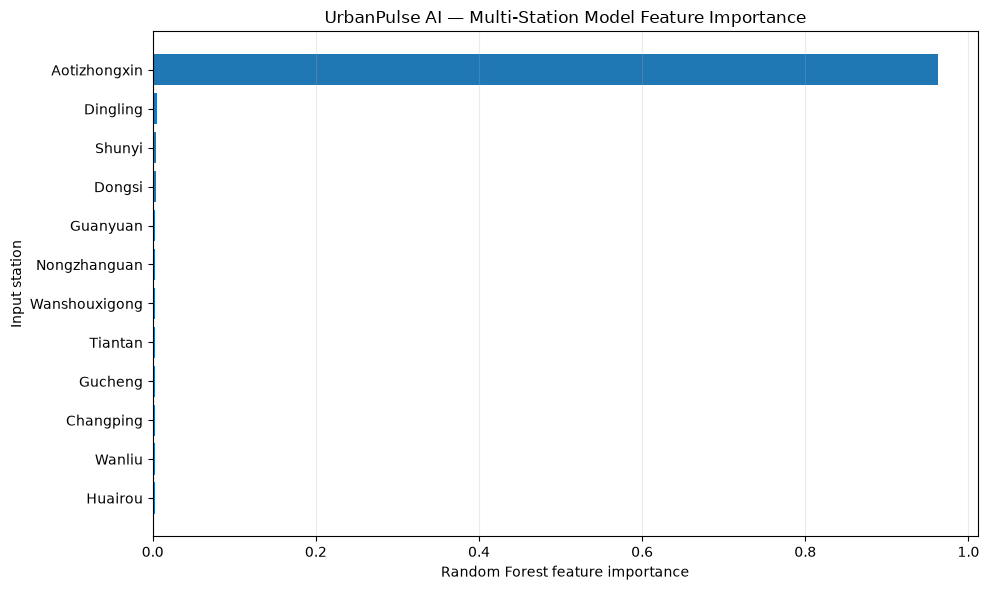

Saved station feature importance.


In [18]:
station_importance = pd.DataFrame({
    "Station": X_train_imputed.columns,
    "Importance": multi_station_model.feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(station_importance.round(5))

plt.figure(figsize=(10, 6))
plt.barh(
    station_importance["Station"][::-1],
    station_importance["Importance"][::-1]
)
plt.xlabel("Random Forest feature importance")
plt.ylabel("Input station")
plt.title("UrbanPulse AI — Multi-Station Model Feature Importance")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

station_importance.to_csv(
    REPORT_DIR / "spatial_station_feature_importance.csv",
    index=False
)

print("Saved station feature importance.")

## 6.5 Test-Set Permutation Importance

### Objective
Evaluate how the multi-station Random Forest's held-out test RMSE changes when the PM2.5 input measurements from individual monitoring stations are permuted.

### Method
- Use the previously trained multi-station Random Forest.
- Keep the test targets and all non-permuted features unchanged.
- Permute one station's feature values at a time.
- Repeat each permutation several times to reduce dependence on one random shuffle.
- Rank stations by the resulting increase in RMSE.

### Interpretation
A larger increase in RMSE indicates greater model reliance on that feature under this permutation procedure. Because monitoring stations are correlated, this is not a causal measure or a definitive estimate of each station's unique contribution.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Confirm that the expected objects exist and have compatible dimensions.
assert "multi_station_model" in globals()
assert "X_test_imputed" in globals()
assert "y_test" in globals()

X_perm_test = X_test_imputed.copy()
y_perm_test = np.asarray(y_test).reshape(-1)

assert len(X_perm_test) == len(y_perm_test)
assert list(X_perm_test.columns) == list(X_test_imputed.columns)

# Baseline performance on the untouched test set.
test_predictions_baseline = multi_station_model.predict(X_perm_test)

baseline_test_rmse = np.sqrt(
    mean_squared_error(y_perm_test, test_predictions_baseline)
)

print(f"Test observations: {len(y_perm_test):,}")
print(f"Baseline test RMSE: {baseline_test_rmse:.4f} µg/m³")
print(f"Number of station features: {X_perm_test.shape[1]}")

Test observations: 5,139
Baseline test RMSE: 19.6072 µg/m³
Number of station features: 12


In [20]:
N_REPEATS = 10
rng = np.random.default_rng(42)

permutation_records = []

for station in X_perm_test.columns:
    rmse_increases = []

    for repeat in range(N_REPEATS):
        X_shuffled = X_perm_test.copy()

        # Shuffle this station's values while keeping other columns unchanged.
        shuffled_values = X_shuffled[station].to_numpy().copy()
        rng.shuffle(shuffled_values)
        X_shuffled[station] = shuffled_values

        shuffled_predictions = multi_station_model.predict(X_shuffled)

        shuffled_rmse = np.sqrt(
            mean_squared_error(y_perm_test, shuffled_predictions)
        )

        rmse_increases.append(shuffled_rmse - baseline_test_rmse)

    permutation_records.append({
        "Station": station,
        "Baseline_Test_RMSE": baseline_test_rmse,
        "Mean_RMSE_Increase": np.mean(rmse_increases),
        "Std_RMSE_Increase": np.std(rmse_increases, ddof=1),
        "Mean_Permuted_RMSE": baseline_test_rmse + np.mean(rmse_increases),
        "Repeats": N_REPEATS
    })

permutation_importance_df = (
    pd.DataFrame(permutation_records)
    .sort_values("Mean_RMSE_Increase", ascending=False)
    .reset_index(drop=True)
)

permutation_importance_df.insert(
    0, "Rank", np.arange(1, len(permutation_importance_df) + 1)
)

display(permutation_importance_df.round(4))

,Rank,Station,Baseline_Test_RMSE,Mean_RMSE_Increase,Std_RMSE_Increase,Mean_Permuted_RMSE,Repeats
0,1,Aotizhongxin,19.6072,81.2024,0.7924,100.8096,10
1,2,Dingling,19.6072,3.5437,0.2167,23.1509,10
2,3,Changping,19.6072,0.8406,0.0495,20.4478,10
3,4,Dongsi,19.6072,0.8135,0.0692,20.4207,10
4,5,Gucheng,19.6072,0.7949,0.0371,20.4020,10
5,6,Shunyi,19.6072,0.7787,0.0448,20.3858,10
6,7,Wanliu,19.6072,0.7030,0.0320,20.3101,10
7,8,Guanyuan,19.6072,0.5310,0.0452,20.1382,10
8,9,Nongzhanguan,19.6072,0.5111,0.0341,20.1183,10
9,10,Tiantan,19.6072,0.4692,0.0510,20.0763,10


In [21]:
from pathlib import Path

REPORTS_DIR = Path(r"C:\UrbanPulse-AI\reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

permutation_output_path = (
    REPORTS_DIR / "spatial_test_permutation_importance.csv"
)

permutation_importance_df.to_csv(
    permutation_output_path,
    index=False
)

print(f"Saved: {permutation_output_path}")

Saved: C:\UrbanPulse-AI\reports\spatial_test_permutation_importance.csv


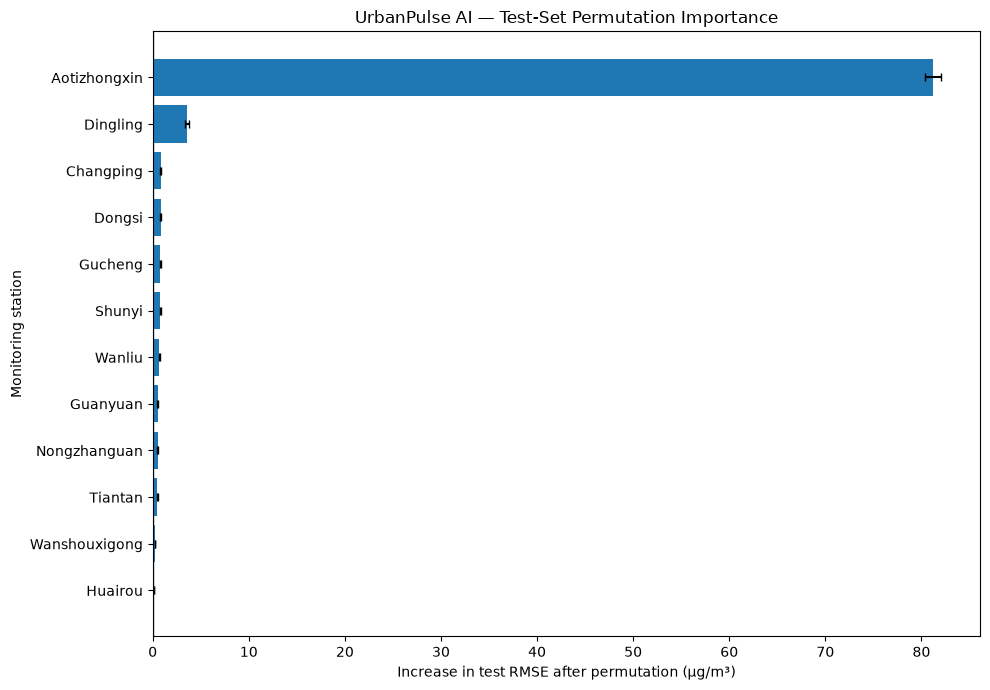

In [22]:
plot_df = permutation_importance_df.sort_values(
    "Mean_RMSE_Increase",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Station"],
    plot_df["Mean_RMSE_Increase"],
    xerr=plot_df["Std_RMSE_Increase"],
    capsize=3
)

plt.axvline(0, linewidth=1)
plt.xlabel("Increase in test RMSE after permutation (µg/m³)")
plt.ylabel("Monitoring station")
plt.title("UrbanPulse AI — Test-Set Permutation Importance")
plt.tight_layout()
plt.show()

In [23]:
print("Top 5 stations by mean test RMSE increase:")
display(
    permutation_importance_df[
        ["Rank", "Station", "Mean_RMSE_Increase", "Std_RMSE_Increase"]
    ].head(5).round(4)
)

print("\nStations with negative mean permutation importance:")
display(
    permutation_importance_df.loc[
        permutation_importance_df["Mean_RMSE_Increase"] < 0,
        ["Station", "Mean_RMSE_Increase", "Std_RMSE_Increase"]
    ].round(4)
)

Top 5 stations by mean test RMSE increase:


,Rank,Station,Mean_RMSE_Increase,Std_RMSE_Increase
0,1,Aotizhongxin,81.2024,0.7924
1,2,Dingling,3.5437,0.2167
2,3,Changping,0.8406,0.0495
3,4,Dongsi,0.8135,0.0692
4,5,Gucheng,0.7949,0.0371



Stations with negative mean permutation importance:


,Station,Mean_RMSE_Increase,Std_RMSE_Increase


## 6.6 Prediction Diagnostics

### Objective
Assess the multi-station Random Forest on the held-out test set using actual-versus-predicted comparisons, residual distributions, pollution-level groups, and monthly performance.

### Residual definition
Residual = Actual PM2.5 − Predicted PM2.5

Positive residuals indicate underprediction; negative residuals indicate overprediction.

All diagnostic analysis uses the existing held-out test predictions. The test set is not used to retrain or tune the models.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

y_actual = np.asarray(y_test).reshape(-1)

pred_persistence = X_test_imputed["Aotizhongxin"].to_numpy()
pred_target_only = target_only_model.predict(
    X_test_imputed[["Aotizhongxin"]]
)
pred_multi_station = multi_station_model.predict(X_test_imputed)

test_diagnostics = pd.DataFrame({
    "Target_Time": pd.to_datetime(target_time_test).to_numpy(),
    "Actual_PM25": y_actual,
    "Persistence_Prediction": pred_persistence,
    "Target_Only_RF_Prediction": pred_target_only,
    "Multi_Station_RF_Prediction": pred_multi_station
})

test_diagnostics["Multi_Station_Residual"] = (
    test_diagnostics["Actual_PM25"]
    - test_diagnostics["Multi_Station_RF_Prediction"]
)

def summarize_predictions(actual, predicted, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Mean_Residual": np.mean(actual - predicted)
    }

diagnostic_metrics = pd.DataFrame([
    summarize_predictions(
        y_actual, pred_persistence, "Persistence"
    ),
    summarize_predictions(
        y_actual, pred_target_only, "Target-only RF"
    ),
    summarize_predictions(
        y_actual, pred_multi_station, "Multi-station RF"
    )
])

display(diagnostic_metrics.round(4))

print("Prediction rows:", len(test_diagnostics))
print("Missing values in diagnostic table:")
display(test_diagnostics.isna().sum())

,Model,MAE,RMSE,R2,Mean_Residual
0,Persistence,11.0272,20.9235,0.9500,0.0099
1,Target-only RF,11.4197,21.1933,0.9487,0.2582
2,Multi-station RF,10.7072,19.6072,0.9561,-0.8097


Prediction rows: 5139
Missing values in diagnostic table:


Target_Time                    0
Actual_PM25                    0
Persistence_Prediction         0
Target_Only_RF_Prediction      0
Multi_Station_RF_Prediction    0
Multi_Station_Residual         0
dtype: int64

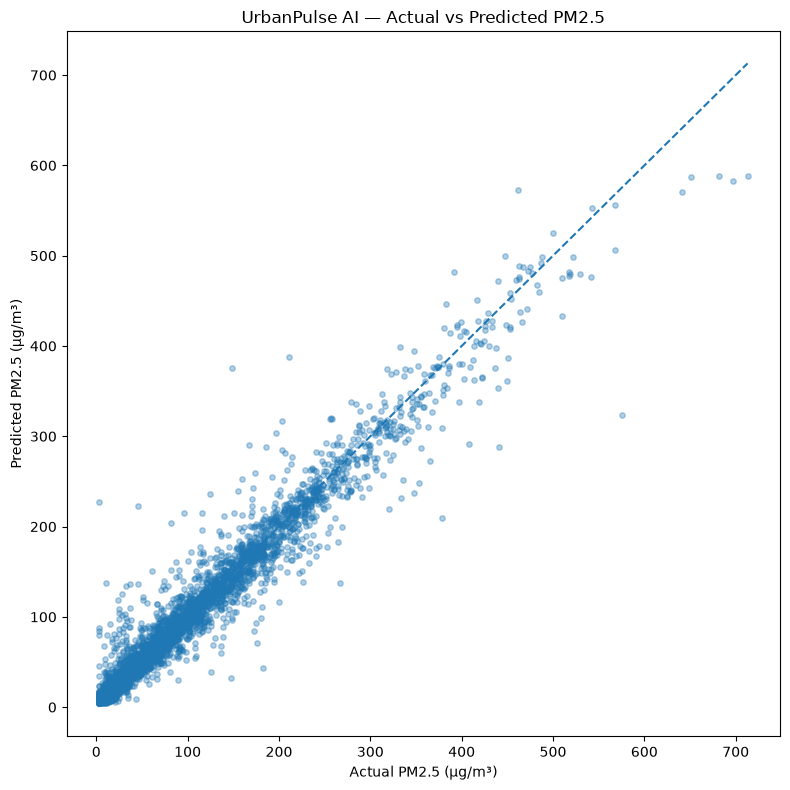

In [25]:
plt.figure(figsize=(8, 8))

plt.scatter(
    test_diagnostics["Actual_PM25"],
    test_diagnostics["Multi_Station_RF_Prediction"],
    alpha=0.35,
    s=15
)

axis_min = min(
    test_diagnostics["Actual_PM25"].min(),
    test_diagnostics["Multi_Station_RF_Prediction"].min()
)
axis_max = max(
    test_diagnostics["Actual_PM25"].max(),
    test_diagnostics["Multi_Station_RF_Prediction"].max()
)

plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title("UrbanPulse AI — Actual vs Predicted PM2.5")
plt.tight_layout()
plt.show()

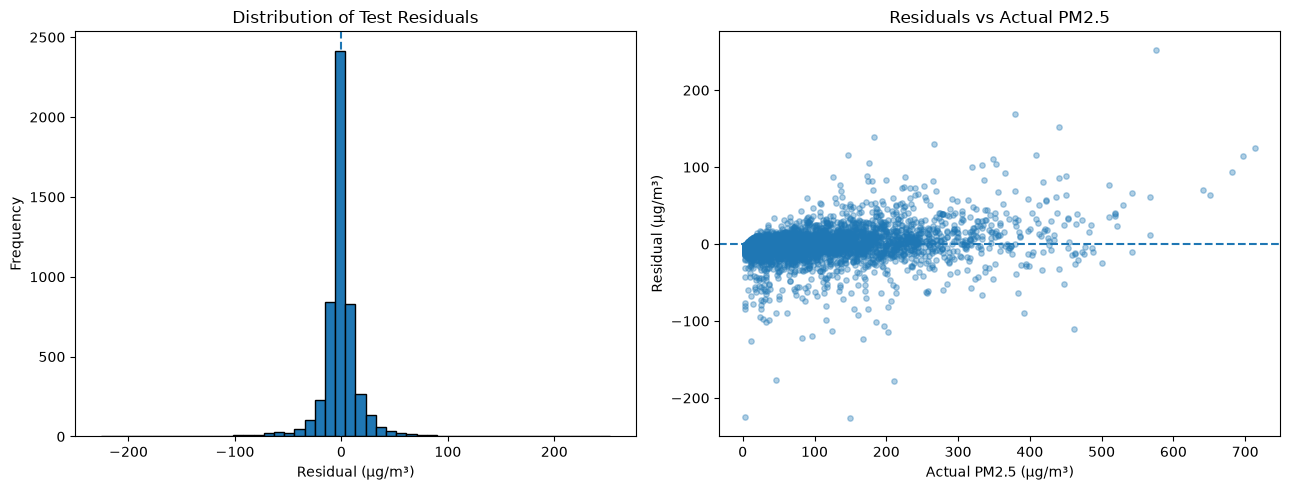

Mean residual: -0.8097 µg/m³
Median residual: -1.0006 µg/m³
Residual standard deviation: 19.5924 µg/m³
Mean absolute residual: 10.7072 µg/m³
Maximum absolute residual: 252.5943 µg/m³


In [26]:
residuals = test_diagnostics["Multi_Station_Residual"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(residuals, bins=50, edgecolor="black")
axes[0].axvline(0, linestyle="--")
axes[0].set_xlabel("Residual (µg/m³)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Test Residuals")

axes[1].scatter(
    test_diagnostics["Actual_PM25"],
    residuals,
    alpha=0.35,
    s=15
)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Actual PM2.5 (µg/m³)")
axes[1].set_ylabel("Residual (µg/m³)")
axes[1].set_title("Residuals vs Actual PM2.5")

plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.4f} µg/m³")
print(f"Median residual: {residuals.median():.4f} µg/m³")
print(f"Residual standard deviation: {residuals.std():.4f} µg/m³")
print(f"Mean absolute residual: {residuals.abs().mean():.4f} µg/m³")
print(f"Maximum absolute residual: {residuals.abs().max():.4f} µg/m³")

In [27]:
pollution_bins = [-np.inf, 35, 75, 150, 250, np.inf]
pollution_labels = [
    "≤35", ">35–75", ">75–150", ">150–250", ">250"
]

test_diagnostics["Actual_PM25_Group"] = pd.cut(
    test_diagnostics["Actual_PM25"],
    bins=pollution_bins,
    labels=pollution_labels,
    right=True
)

level_records = []

for group, group_df in test_diagnostics.groupby(
    "Actual_PM25_Group", observed=False
):
    if len(group_df) == 0:
        continue

    actual = group_df["Actual_PM25"]
    predicted = group_df["Multi_Station_RF_Prediction"]

    level_records.append({
        "Actual_PM25_Group": str(group),
        "Observations": len(group_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Mean_Residual": (actual - predicted).mean()
    })

pollution_level_metrics = pd.DataFrame(level_records)
display(pollution_level_metrics.round(4))

,Actual_PM25_Group,Observations,MAE,RMSE,Mean_Residual
0,≤35,2063,5.6788,12.1895,-3.5826
1,>35–75,1000,8.8783,14.7173,-3.8149
2,>75–150,1067,12.4095,20.0070,-0.2969
3,>150–250,679,17.6416,26.5806,3.9973
4,>250,330,27.9118,40.6644,14.0825


,Month,Observations,MAE,RMSE,Mean_Residual
0,2016-07,140,10.6773,16.6110,-2.8128
1,2016-08,732,6.6672,10.1800,-2.2491
2,2016-09,690,7.2549,12.0320,-1.7076
3,2016-10,735,8.8748,14.4645,-1.1769
4,2016-11,711,12.0488,21.0105,-0.1681
5,2016-12,742,16.1628,26.5869,1.8932
6,2017-01,742,14.2896,26.9669,-1.3447
7,2017-02,647,9.2083,18.8355,-0.5645


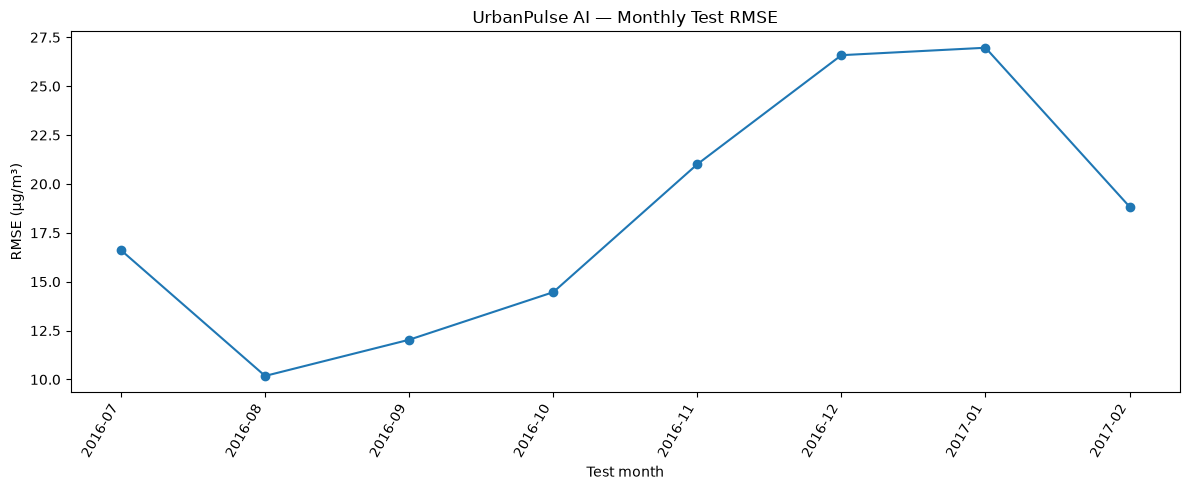

In [28]:
test_diagnostics["Month"] = (
    test_diagnostics["Target_Time"].dt.to_period("M").astype(str)
)

monthly_records = []

for month, month_df in test_diagnostics.groupby("Month", sort=True):
    actual = month_df["Actual_PM25"]
    predicted = month_df["Multi_Station_RF_Prediction"]

    monthly_records.append({
        "Month": month,
        "Observations": len(month_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Mean_Residual": (actual - predicted).mean()
    })

monthly_test_metrics = pd.DataFrame(monthly_records)
display(monthly_test_metrics.round(4))

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_test_metrics["Month"],
    monthly_test_metrics["RMSE"],
    marker="o"
)
plt.xticks(rotation=60, ha="right")
plt.xlabel("Test month")
plt.ylabel("RMSE (µg/m³)")
plt.title("UrbanPulse AI — Monthly Test RMSE")
plt.tight_layout()
plt.show()

In [29]:
reports_dir = Path(r"C:\UrbanPulse-AI\reports")
reports_dir.mkdir(parents=True, exist_ok=True)

test_diagnostics.to_csv(
    reports_dir / "spatial_test_predictions_diagnostics.csv",
    index=False
)

diagnostic_metrics.to_csv(
    reports_dir / "spatial_test_diagnostic_metrics.csv",
    index=False
)

pollution_level_metrics.to_csv(
    reports_dir / "spatial_test_metrics_by_pollution_level.csv",
    index=False
)

monthly_test_metrics.to_csv(
    reports_dir / "spatial_test_monthly_metrics.csv",
    index=False
)

print("Saved:")
print(reports_dir / "spatial_test_predictions_diagnostics.csv")
print(reports_dir / "spatial_test_diagnostic_metrics.csv")
print(reports_dir / "spatial_test_metrics_by_pollution_level.csv")
print(reports_dir / "spatial_test_monthly_metrics.csv")

Saved:
C:\UrbanPulse-AI\reports\spatial_test_predictions_diagnostics.csv
C:\UrbanPulse-AI\reports\spatial_test_diagnostic_metrics.csv
C:\UrbanPulse-AI\reports\spatial_test_metrics_by_pollution_level.csv
C:\UrbanPulse-AI\reports\spatial_test_monthly_metrics.csv


## 6.6 Prediction Diagnostics

### Objective
Assess the multi-station Random Forest on the held-out test set using actual-versus-predicted comparisons, residual distributions, pollution-level groups, and monthly performance.

### Residual definition
Residual = Actual PM2.5 − Predicted PM2.5

Positive residuals indicate underprediction; negative residuals indicate overprediction.

All diagnostic analysis uses the existing held-out test predictions. The test set is not used to retrain or tune the models.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

y_actual = np.asarray(y_test).reshape(-1)

pred_persistence = X_test_imputed["Aotizhongxin"].to_numpy()
pred_target_only = target_only_model.predict(
    X_test_imputed[["Aotizhongxin"]]
)
pred_multi_station = multi_station_model.predict(X_test_imputed)

test_diagnostics = pd.DataFrame({
    "Target_Time": pd.to_datetime(target_time_test).to_numpy(),
    "Actual_PM25": y_actual,
    "Persistence_Prediction": pred_persistence,
    "Target_Only_RF_Prediction": pred_target_only,
    "Multi_Station_RF_Prediction": pred_multi_station
})

test_diagnostics["Multi_Station_Residual"] = (
    test_diagnostics["Actual_PM25"]
    - test_diagnostics["Multi_Station_RF_Prediction"]
)

def summarize_predictions(actual, predicted, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Mean_Residual": np.mean(actual - predicted)
    }

diagnostic_metrics = pd.DataFrame([
    summarize_predictions(
        y_actual, pred_persistence, "Persistence"
    ),
    summarize_predictions(
        y_actual, pred_target_only, "Target-only RF"
    ),
    summarize_predictions(
        y_actual, pred_multi_station, "Multi-station RF"
    )
])

display(diagnostic_metrics.round(4))

print("Prediction rows:", len(test_diagnostics))
print("Missing values in diagnostic table:")
display(test_diagnostics.isna().sum())

,Model,MAE,RMSE,R2,Mean_Residual
0,Persistence,11.0272,20.9235,0.9500,0.0099
1,Target-only RF,11.4197,21.1933,0.9487,0.2582
2,Multi-station RF,10.7072,19.6072,0.9561,-0.8097


Prediction rows: 5139
Missing values in diagnostic table:


Target_Time                    0
Actual_PM25                    0
Persistence_Prediction         0
Target_Only_RF_Prediction      0
Multi_Station_RF_Prediction    0
Multi_Station_Residual         0
dtype: int64

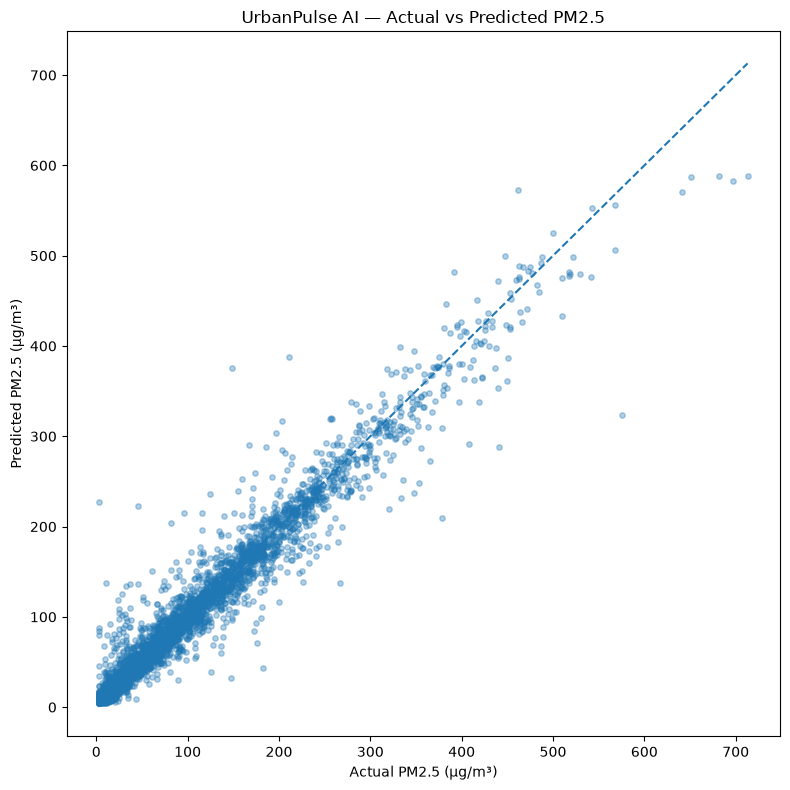

In [31]:
plt.figure(figsize=(8, 8))

plt.scatter(
    test_diagnostics["Actual_PM25"],
    test_diagnostics["Multi_Station_RF_Prediction"],
    alpha=0.35,
    s=15
)

axis_min = min(
    test_diagnostics["Actual_PM25"].min(),
    test_diagnostics["Multi_Station_RF_Prediction"].min()
)
axis_max = max(
    test_diagnostics["Actual_PM25"].max(),
    test_diagnostics["Multi_Station_RF_Prediction"].max()
)

plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title("UrbanPulse AI — Actual vs Predicted PM2.5")
plt.tight_layout()
plt.show()

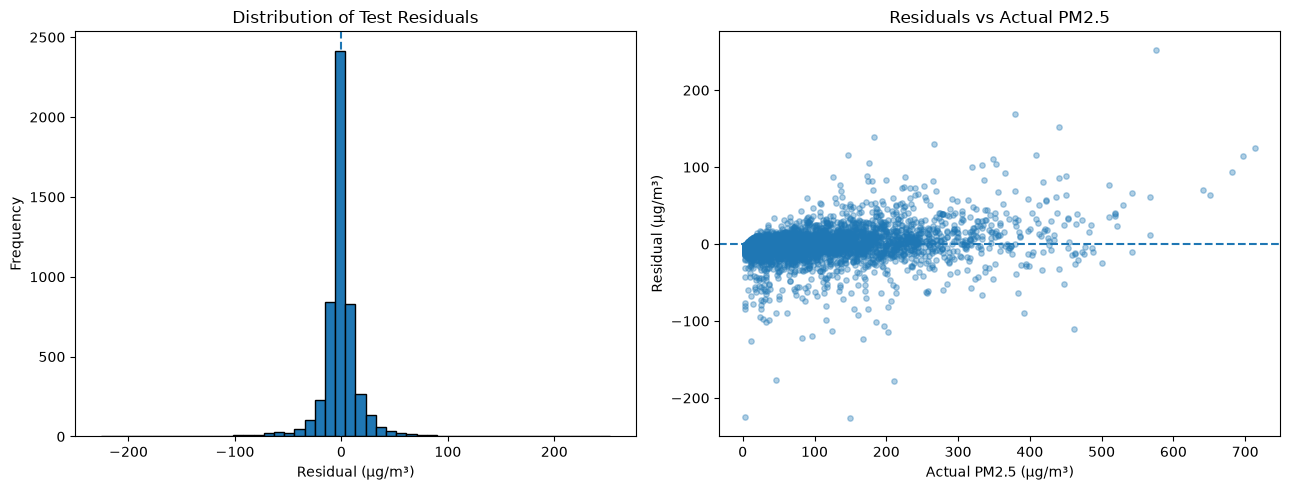

Mean residual: -0.8097 µg/m³
Median residual: -1.0006 µg/m³
Residual standard deviation: 19.5924 µg/m³
Mean absolute residual: 10.7072 µg/m³
Maximum absolute residual: 252.5943 µg/m³


In [32]:
residuals = test_diagnostics["Multi_Station_Residual"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(residuals, bins=50, edgecolor="black")
axes[0].axvline(0, linestyle="--")
axes[0].set_xlabel("Residual (µg/m³)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Test Residuals")

axes[1].scatter(
    test_diagnostics["Actual_PM25"],
    residuals,
    alpha=0.35,
    s=15
)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Actual PM2.5 (µg/m³)")
axes[1].set_ylabel("Residual (µg/m³)")
axes[1].set_title("Residuals vs Actual PM2.5")

plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.4f} µg/m³")
print(f"Median residual: {residuals.median():.4f} µg/m³")
print(f"Residual standard deviation: {residuals.std():.4f} µg/m³")
print(f"Mean absolute residual: {residuals.abs().mean():.4f} µg/m³")
print(f"Maximum absolute residual: {residuals.abs().max():.4f} µg/m³")

In [33]:
pollution_bins = [-np.inf, 35, 75, 150, 250, np.inf]
pollution_labels = [
    "≤35", ">35–75", ">75–150", ">150–250", ">250"
]

test_diagnostics["Actual_PM25_Group"] = pd.cut(
    test_diagnostics["Actual_PM25"],
    bins=pollution_bins,
    labels=pollution_labels,
    right=True
)

level_records = []

for group, group_df in test_diagnostics.groupby(
    "Actual_PM25_Group", observed=False
):
    if len(group_df) == 0:
        continue

    actual = group_df["Actual_PM25"]
    predicted = group_df["Multi_Station_RF_Prediction"]

    level_records.append({
        "Actual_PM25_Group": str(group),
        "Observations": len(group_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Mean_Residual": (actual - predicted).mean()
    })

pollution_level_metrics = pd.DataFrame(level_records)
display(pollution_level_metrics.round(4))

,Actual_PM25_Group,Observations,MAE,RMSE,Mean_Residual
0,≤35,2063,5.6788,12.1895,-3.5826
1,>35–75,1000,8.8783,14.7173,-3.8149
2,>75–150,1067,12.4095,20.0070,-0.2969
3,>150–250,679,17.6416,26.5806,3.9973
4,>250,330,27.9118,40.6644,14.0825


,Month,Observations,MAE,RMSE,Mean_Residual
0,2016-07,140,10.6773,16.6110,-2.8128
1,2016-08,732,6.6672,10.1800,-2.2491
2,2016-09,690,7.2549,12.0320,-1.7076
3,2016-10,735,8.8748,14.4645,-1.1769
4,2016-11,711,12.0488,21.0105,-0.1681
5,2016-12,742,16.1628,26.5869,1.8932
6,2017-01,742,14.2896,26.9669,-1.3447
7,2017-02,647,9.2083,18.8355,-0.5645


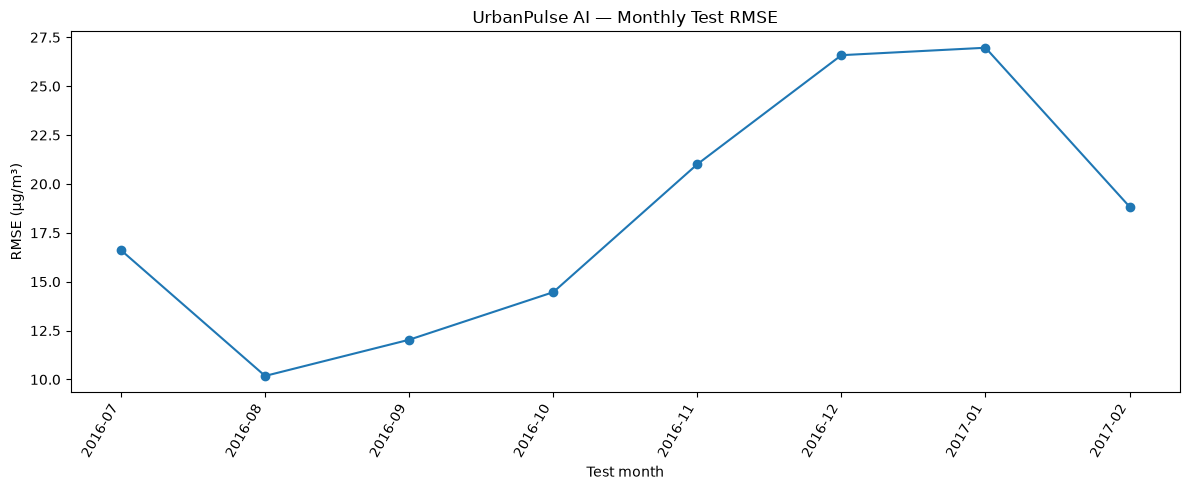

In [34]:
test_diagnostics["Month"] = (
    test_diagnostics["Target_Time"].dt.to_period("M").astype(str)
)

monthly_records = []

for month, month_df in test_diagnostics.groupby("Month", sort=True):
    actual = month_df["Actual_PM25"]
    predicted = month_df["Multi_Station_RF_Prediction"]

    monthly_records.append({
        "Month": month,
        "Observations": len(month_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Mean_Residual": (actual - predicted).mean()
    })

monthly_test_metrics = pd.DataFrame(monthly_records)
display(monthly_test_metrics.round(4))

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_test_metrics["Month"],
    monthly_test_metrics["RMSE"],
    marker="o"
)
plt.xticks(rotation=60, ha="right")
plt.xlabel("Test month")
plt.ylabel("RMSE (µg/m³)")
plt.title("UrbanPulse AI — Monthly Test RMSE")
plt.tight_layout()
plt.show()

In [35]:
reports_dir = Path(r"C:\UrbanPulse-AI\reports")
reports_dir.mkdir(parents=True, exist_ok=True)

test_diagnostics.to_csv(
    reports_dir / "spatial_test_predictions_diagnostics.csv",
    index=False
)

diagnostic_metrics.to_csv(
    reports_dir / "spatial_test_diagnostic_metrics.csv",
    index=False
)

pollution_level_metrics.to_csv(
    reports_dir / "spatial_test_metrics_by_pollution_level.csv",
    index=False
)

monthly_test_metrics.to_csv(
    reports_dir / "spatial_test_monthly_metrics.csv",
    index=False
)

print("Saved:")
print(reports_dir / "spatial_test_predictions_diagnostics.csv")
print(reports_dir / "spatial_test_diagnostic_metrics.csv")
print(reports_dir / "spatial_test_metrics_by_pollution_level.csv")
print(reports_dir / "spatial_test_monthly_metrics.csv")

Saved:
C:\UrbanPulse-AI\reports\spatial_test_predictions_diagnostics.csv
C:\UrbanPulse-AI\reports\spatial_test_diagnostic_metrics.csv
C:\UrbanPulse-AI\reports\spatial_test_metrics_by_pollution_level.csv
C:\UrbanPulse-AI\reports\spatial_test_monthly_metrics.csv


## 6.7 Spatial Modeling Conclusions

### Objective
Summarize the spatial distribution of monitoring stations, inter-station PM2.5 relationships, and the performance of multi-station forecasting.

### Dataset integration and quality
The Beijing Multi-Site Air Quality dataset contains 12 monitoring stations with 35,064 hourly records per station, covering March 2013 through February 2017. The integrated dataset contains 420,768 station-hour records. Duplicate station-timestamp pairs and invalid timestamps were not detected in the integration checks.

PM2.5 missingness varies by station. The spatial analysis therefore uses explicit eligibility checks and training-only median imputation for missing predictor values rather than requiring all 12 stations to have complete measurements at every hour.

### Geographic analysis
Published approximate coordinates were associated with the monitoring stations to examine their geographic distribution and pairwise distances. Several stations are clustered in central Beijing, while others extend coverage to northern, eastern, and western areas. The coordinates represent approximate published locations, not newly measured coordinates.

### Inter-station relationships
Simultaneous PM2.5 measurements showed positive Pearson correlations across all station pairs, ranging approximately from 0.778 to 0.969. These associations indicate that pollution measurements often co-vary across the monitoring network. Correlation alone does not establish geographic proximity, causal relationships, or the unique contribution of individual stations.

### Forecasting experiment
The forecasting task predicts Aotizhongxin PM2.5 one hour ahead using current-hour station measurements. Data were divided chronologically into training, validation, and held-out test partitions. The multi-station Random Forest was compared with persistence and target-station-only Random Forest baselines.

On the held-out test set, the multi-station Random Forest achieved:
- MAE: 10.7072 µg/m³
- RMSE: 19.6072 µg/m³
- R²: 0.9561

The persistence baseline achieved MAE of 11.0272 µg/m³, RMSE of 20.9235 µg/m³, and R² of 0.9500. The target-station-only Random Forest achieved MAE of 11.4197 µg/m³, RMSE of 21.1933 µg/m³, and R² of 0.9487.

The multi-station model therefore improved test RMSE by approximately 6.29% relative to persistence and 7.48% relative to the target-station-only Random Forest. These findings support the usefulness of multi-station inputs for this forecasting setup, but do not establish that every station contributes equally or that the results will generalize to other cities.

### Feature importance and error analysis
Impurity-based and permutation-based importance analyses both showed strong reliance on Aotizhongxin's current PM2.5 measurement. Dingling was the second most influential station in the permutation analysis, while the remaining stations had smaller individual permutation effects. Because stations are correlated, these rankings should not be interpreted as definitive estimates of unique spatial contributions.

Prediction diagnostics showed increasing MAE and RMSE across higher actual PM2.5 groups. The group above 250 µg/m³ had MAE of 27.9118 µg/m³ and RMSE of 40.6644 µg/m³. Its positive mean residual of 14.0825 µg/m³ indicates average underprediction in that group. Monthly test RMSE also varied, with higher errors in December 2016 and January 2017.

### Limitations
1. The experiment uses one target station and a one-hour forecast horizon.
2. Station coordinates are approximate and were obtained from published research.
3. Correlated station measurements complicate the interpretation of feature importance.
4. The model's performance is weaker at high PM2.5 concentrations.
5. The analysis does not establish causal effects of weather, geography, or emissions.
6. Results from one historical Beijing dataset should not be assumed to generalize to other locations or time periods.

### Conclusion
The spatial modeling experiment demonstrates that a multi-station Random Forest can improve one-hour-ahead PM2.5 prediction at Aotizhongxin relative to the tested persistence and target-only Random Forest baselines. The results also highlight limitations in predicting high-concentration pollution events and interpreting individual station importance in a correlated monitoring network. These findings provide a foundation for further spatial modeling and evaluation.

In [36]:
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

expected_artifacts = [
    "reports/spatial_station_quality.csv",
    "reports/spatial_pm25_correlation.csv",
    "reports/spatial_station_coordinates.csv",
    "reports/spatial_station_distance_matrix_km.csv",
    "reports/spatial_forecasting_metrics.csv",
    "reports/spatial_model_improvement.csv",
    "reports/spatial_station_feature_importance.csv",
    "reports/spatial_test_permutation_importance.csv",
    "reports/spatial_test_predictions_diagnostics.csv",
    "reports/spatial_test_diagnostic_metrics.csv",
    "reports/spatial_test_metrics_by_pollution_level.csv",
    "reports/spatial_test_monthly_metrics.csv",
]

artifact_check = pd.DataFrame([
    {
        "Artifact": name,
        "Exists": (project_dir / name).exists(),
        "Size_Bytes": (
            (project_dir / name).stat().st_size
            if (project_dir / name).exists()
            else None
        )
    }
    for name in expected_artifacts
])

display(artifact_check)
print(
    f"Existing artifacts: {artifact_check['Exists'].sum()}"
    f" / {len(artifact_check)}"
)

,Artifact,Exists,Size_Bytes
0,reports/spatial_station_quality.csv,True,1065
1,reports/spatial_pm25_correlation.csv,True,2787
2,reports/spatial_station_coordinates.csv,True,331
3,reports/spatial_station_distance_matrix_km.csv,True,2720
4,reports/spatial_forecasting_metrics.csv,True,505
5,reports/spatial_model_improvement.csv,True,363
6,reports/spatial_station_feature_importance.csv,True,402
7,reports/spatial_test_permutation_importance.csv,True,1207
8,reports/spatial_test_predictions_diagnostics.csv,True,530603
9,reports/spatial_test_diagnostic_metrics.csv,True,305


Existing artifacts: 12 / 12


In [37]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Random Forest models:")
for name, obj in list(globals().items()):
    if isinstance(obj, RandomForestRegressor):
        print(f"  {name}: {obj}")

print("\nPipelines containing a Random Forest:")
for name, obj in list(globals().items()):
    if isinstance(obj, Pipeline):
        if any(
            isinstance(step, RandomForestRegressor)
            for _, step in obj.steps
        ):
            print(f"  {name}: {obj}")

print("\nImputers:")
for name, obj in list(globals().items()):
    if isinstance(obj, SimpleImputer):
        print(f"  {name}: {obj}")

Random Forest models:
  target_only_model: RandomForestRegressor(max_depth=16, min_samples_leaf=5, n_estimators=300,
                      n_jobs=-1, random_state=42)
  multi_station_model: RandomForestRegressor(max_depth=16, min_samples_leaf=5, n_estimators=300,
                      n_jobs=-1, random_state=42)

Pipelines containing a Random Forest:

Imputers:
  spatial_imputer: SimpleImputer(strategy='median')


In [38]:
from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path(r"C:\UrbanPulse-AI")
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the already-trained models and fitted preprocessing component.
joblib.dump(
    multi_station_model,
    MODELS_DIR / "urbanpulse_spatial_rf.joblib"
)

joblib.dump(
    spatial_imputer,
    MODELS_DIR / "urbanpulse_spatial_imputer.joblib"
)

joblib.dump(
    target_only_model,
    MODELS_DIR / "urbanpulse_target_only_rf.joblib"
)

# Record the model configuration and expected feature order.
model_metadata = {
    "project": "UrbanPulse AI",
    "model_type": "RandomForestRegressor",
    "model_file": "urbanpulse_spatial_rf.joblib",
    "imputer_file": "urbanpulse_spatial_imputer.joblib",
    "target": "Aotizhongxin PM2.5 one hour ahead",
    "forecast_horizon_hours": 1,
    "input_features": list(spatial_imputer.feature_names_in_),
    "n_features": len(spatial_imputer.feature_names_in_),
    "random_state": 42,
    "n_estimators": 300,
    "max_depth": 16,
    "min_samples_leaf": 5
}

with open(
    REPORTS_DIR / "spatial_rf_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(model_metadata, f, indent=2)

print("Saved artifacts:")
for filename in [
    "urbanpulse_spatial_rf.joblib",
    "urbanpulse_spatial_imputer.joblib",
    "urbanpulse_target_only_rf.joblib",
]:
    path = MODELS_DIR / filename
    print(f"{filename}: {path.exists()} ({path.stat().st_size:,} bytes)")

print("\nFeature order:")
print(model_metadata["input_features"])

Saved artifacts:
urbanpulse_spatial_rf.joblib: True (78,121,409 bytes)
urbanpulse_spatial_imputer.joblib: True (983 bytes)
urbanpulse_target_only_rf.joblib: True (14,537,233 bytes)

Feature order:
['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
